# Tabular — Cek Input: Outlier dan Nilai Mustahil Sebelum Modeling
**Kapan dipakai:** data hasil entri manual yang mungkin berisi salah ketik, salah satuan,
angka 0, atau tanda minus.

**Tiga lapis cek:**
1. **Aturan domain**: nilai mustahil, rumus yang harus konsisten.
2. **Per kolom**: IQR dan robust z.
3. **Multivariat**: IsolationForest / LOF, untuk baris yang kombinasinya aneh walau tiap
   kolom terlihat wajar.

Lalu baris curiga ditangani: dijadikan NaN, dibuang, atau dibiarkan.

**Data demo:** Diamonds (`price`). Sel **Simulasi** sengaja merusak 3% baris agar ketepatan
detektor bisa diukur. **HAPUS sel itu saat lomba.**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, RobustScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/tabular/regression"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/diamonds_train.csv"
TEST_CSV = f"{DATA_FOLDER}/diamonds_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/diamonds_test_labels.csv"   # hanya ada di data latihan

TARGET = "price"
NUM_COLS = ["carat", "depth", "table", "x", "y", "z"]
CAT_COLS = ["cut", "color", "clarity"]
SUSPECT_SHARE = 0.03   # perkiraan proporsi baris rusak (untuk detektor multivariat)
ROBUST_Z_LIMIT = 5     # robust z di atas ini = outlier
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
FEATURES = CAT_COLS + NUM_COLS
print("train:", train.shape, "| test:", test.shape)
train[NUM_COLS].describe().round(2)

train: (4800, 11) | test: (1200, 10)


,carat,depth,table,x,y,z
count,4800.00,4800.00,4800.00,4800.00,4800.00,4800.00
mean,0.79,61.71,57.45,5.72,5.72,3.53
std,0.46,1.46,2.28,1.11,1.10,0.69
min,0.23,44.00,51.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,5.69,5.70,3.52
75%,1.04,62.50,59.00,6.53,6.54,4.03
max,4.13,71.60,95.00,10.00,9.85,6.43


## Simulasi kesalahan input — **HAPUS sel ini saat lomba**
Kesalahan khas data entri: salah ketik ×10, satuan salah (÷100), angka 0, tanda minus.
`is_broken` = penanda baris yang dirusak (kunci untuk mengukur detektor).

In [4]:
random_generator = np.random.default_rng(SEED)
is_broken = pd.Series(random_generator.random(len(train)) < 0.03, index=train.index)
error_factors = [10, 0.01, 0, -1]
for i in train.index[is_broken]:
    col = random_generator.choice(NUM_COLS)
    factor = random_generator.choice(error_factors)
    train.loc[i, col] = train.loc[i, col] * factor
print("baris dirusak:", is_broken.sum())

baris dirusak: 130


## Lapis 1: aturan domain
Tulis sesuai soal, contoh: umur 0–100, harga > 0. Untuk berlian: ukuran harus positif,
depth dan table antara 40–80, depth harus cocok dengan rumus dari x, y, z.

In [5]:
def check_rules(table):
    broken = pd.DataFrame(index=table.index)
    broken["ukuran_tidak_positif"] = (table[["carat", "x", "y", "z"]] <= 0).any(axis=1)
    broken["depth_di_luar_40_80"] = ~table["depth"].between(40, 80)
    broken["table_di_luar_40_80"] = ~table["table"].between(40, 80)
    computed_depth = 2 * table["z"] / (table["x"] + table["y"]) * 100
    broken["depth_tidak_konsisten"] = (table["depth"] - computed_depth).abs() > 5
    return broken


rule_table = check_rules(train)
rule_flags = rule_table.any(axis=1)
print(rule_table.sum())

ukuran_tidak_positif     45
depth_di_luar_40_80      20
table_di_luar_40_80      22
depth_tidak_konsisten    94
dtype: int64


## Lapis 2: per kolom — IQR dan robust z
- IQR: di luar Q1 − 3×IQR sampai Q3 + 3×IQR.
- Robust z: jarak dari median dibagi MAD (versi z-score yang tahan outlier).

In [6]:
q1 = train[NUM_COLS].quantile(0.25)
q3 = train[NUM_COLS].quantile(0.75)
iqr = q3 - q1
outside_iqr = (train[NUM_COLS] < q1 - 3 * iqr) | (train[NUM_COLS] > q3 + 3 * iqr)
iqr_flags = outside_iqr.any(axis=1)

median = train[NUM_COLS].median()
mad = (train[NUM_COLS] - median).abs().median()
robust_z = ((train[NUM_COLS] - median) / (1.4826 * mad)).abs()
robust_z_flags = (robust_z > ROBUST_Z_LIMIT).any(axis=1)

print("ditandai IQR:", iqr_flags.sum(), "| ditandai robust z:", robust_z_flags.sum())

ditandai IQR: 105 | ditandai robust z: 119


## Lapis 3: multivariat
Pilih SATU detektor: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [7]:
X_num = RobustScaler().fit_transform(train[NUM_COLS])
detector = IsolationForest(contamination=SUSPECT_SHARE, random_state=SEED)
# detector = LocalOutlierFactor(n_neighbors=30, contamination=SUSPECT_SHARE)   # berbasis tetangga
multivariate_flags = pd.Series(detector.fit_predict(X_num) == -1, index=train.index)
print("curiga multivariat:", multivariate_flags.sum())

curiga multivariat: 144


## Gabungkan penanda + ukur ketepatannya (memakai kunci simulasi, hanya untuk latihan)
Pilih SATU gabungan. Di demo ini kesalahan terjadi per kolom, jadi aturan + IQR lebih tepat
daripada multivariat.

In [8]:
suspicious = rule_flags | iqr_flags
# suspicious = rule_flags | robust_z_flags
# suspicious = rule_flags | multivariate_flags

print("baris curiga:", suspicious.sum())
print("precision:", round(precision_score(is_broken, suspicious), 2),
      "| recall:", round(recall_score(is_broken, suspicious), 2))

baris curiga: 160
precision: 0.78 | recall: 0.96


## Lihat baris curiga (selalu cek manual sebelum dibuang)

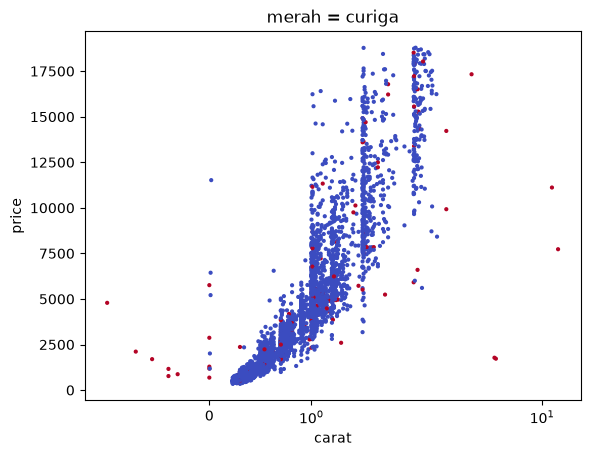

,id,carat,cut,color,clarity,depth,table,price,x,y,z
36,4293,1.01,Fair,F,SI2,67.300,62.00,3597,6.0900,6.03,4.08
51,839,1.21,Premium,G,VVS2,61.300,56.00,9779,0.0688,6.85,4.21
84,3107,5.60,Very Good,H,VVS2,59.800,57.00,1723,5.3900,5.48,3.25
135,2620,0.94,Premium,F,SI2,62.400,580.00,3456,6.2300,6.17,3.87
149,5857,0.31,Ideal,H,IF,0.621,54.00,816,4.3300,4.37,2.70
204,2229,0.30,Very Good,D,VVS2,60.600,-58.00,2366,4.3300,4.35,2.63
226,2132,0.90,Fair,H,VS2,64.700,58.00,3697,5.9800,6.01,0.00
269,1696,0.90,Very Good,F,SI1,63.000,60.00,4232,6.0900,0.00,3.85
326,71,0.50,Fair,E,SI2,68.600,56.00,871,4.8700,4.75,3.30
394,2764,0.34,Very Good,G,SI1,61.500,0.56,507,4.4500,4.52,2.76


In [9]:
plt.scatter(train["carat"], train[TARGET], s=4, c=suspicious, cmap="coolwarm")
plt.xscale("symlog")
plt.xlabel("carat")
plt.ylabel(TARGET)
plt.title("merah = curiga")
plt.show()
train[suspicious].head(10)

## Tindakan: jadikan NaN
Sel yang mustahil (≤ 0) atau robust z terlalu besar dikosongkan; LightGBM bisa menangani
NaN sendiri. Fungsi yang sama dipakai untuk validasi dan test, karena baris **test** tidak
boleh dibuang.

In [10]:
def make_nan(table):
    z_values = ((table[NUM_COLS] - median) / (1.4826 * mad)).abs()
    impossible = (z_values > ROBUST_Z_LIMIT) | (table[NUM_COLS] <= 0)
    table = table.copy()
    table[NUM_COLS] = table[NUM_COLS].mask(impossible)
    return table


# coba pada 3 baris curiga pertama
make_nan(train[suspicious].head(3))[NUM_COLS]

,carat,depth,table,x,y,z
36,1.01,NaN,62.0,6.0900,6.03,4.08
51,1.21,61.3,56.0,0.0688,6.85,4.21
84,NaN,59.8,57.0,5.3900,5.48,3.25


## Model + validasi
Pilih SATU cara menangani data train: hapus `#` di baris yang ingin dipakai.

In [11]:
train_part, val_part = train_test_split(train, test_size=0.25, random_state=SEED)
val_part = make_nan(val_part)

clean_train = make_nan(train_part)
# clean_train = train_part[~suspicious[train_part.index]]   # buang baris curiga
# clean_train = train_part                                  # biarkan apa adanya

preprocess = ColumnTransformer([("cat", OrdinalEncoder(), CAT_COLS)], remainder="passthrough")
model = LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1)
pipe = make_pipeline(preprocess, model)
pipe.fit(clean_train[FEATURES], clean_train[TARGET])

val_predictions = pipe.predict(val_part[FEATURES])
print("RMSE validasi:", round(root_mean_squared_error(val_part[TARGET], val_predictions), 1))

RMSE validasi: 768.4


## Latih ulang di semua data + submission

In [12]:
clean_all = make_nan(train)
# clean_all = train[~suspicious]   # bila memilih "buang baris"
test_clean = make_nan(test)
print("baris test melanggar aturan:", check_rules(test).any(axis=1).sum())
nan_per_column = test_clean[NUM_COLS].isna().sum()
print("sel test dijadikan NaN:", nan_per_column.sum())

pipe.fit(clean_all[FEATURES], clean_all[TARGET])
predictions = pipe.predict(test_clean[FEATURES])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["price"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

baris test melanggar aturan: 1
sel test dijadikan NaN: 8


,id,price
0,1783,4371.946414
1,3918,5189.162743
2,222,2753.956146
3,2136,15726.806115
4,5225,909.476400


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [13]:
test_key = pd.read_csv(TEST_KEY_CSV)["price"]
print("RMSE test (kunci latihan):", round(root_mean_squared_error(test_key, predictions), 1))

RMSE test (kunci latihan): 659.4
